In [ ]:
import html
import os
import re
import subprocess
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# ==============================================================================
# 0. ENSURE DEPENDENCIES ARE INSTALLED
# ==============================================================================
try:
    import openpyxl
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "openpyxl"])

# ==============================================================================
# 1. MOUNT GOOGLE DRIVE & RESOLVE FILE PATHS
# ==============================================================================
try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except ImportError:
    pass  # Running outside Colab

DATA_DIRS = [
    Path("/content/drive/MyDrive/TA2"),
    Path("."),
]


def resolve_path(filename: str) -> Path:
    for folder in DATA_DIRS:
        candidate = folder / filename
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find '{filename}' in {[str(d) for d in DATA_DIRS]}"
    )


# ==============================================================================
# 2. CANONICAL LABEL TAXONOMIES
# ==============================================================================
CANONICAL_POST_LABELS = [
    "Early Dating",
    "Breakups",
    "Communication",
    "Trust",
    "Boundaries",
    "Conflict",
    "Sex/Intimacy",
    "Other",
]

CANONICAL_COMMENT_LABELS = [
    "Dating Strategy",
    "Leave/Disengage",
    "Talk it through",
    "Set boundary",
    "Repair/Help",
    "Wait/More info",
    "No advice",
    "Other",
]


def normalize_label(val, canonical_list: list[str]):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if not s or s.lower() == "nan":
        return np.nan
    return s if s in canonical_list else "Other"

# ==============================================================================
# 3. ID STANDARDIZATION, TEXT CLEANING & DEDUPLICATION
# ==============================================================================
def normalize_reddit_id(s: pd.Series) -> pd.Series:
    """Normalizes Reddit base-36 IDs (strips t1_/t3_ prefixes, .0 float suffixes, and whitespace)."""
    cleaned = (
        s.astype(str)
        .str.strip()
        .str.replace(r"^t[13]_", "", regex=True)
        .str.replace(r"\.0$", "", regex=True)
    )
    invalid = cleaned.str.lower().isin(["", "nan", "none", "null", "na", "<na>"])
    return cleaned.where(~invalid, np.nan)


def standardize_id_columns(df: pd.DataFrame, is_post: bool) -> pd.DataFrame:
    """Maps varying ID column names into canonical `id` (and `parentPostId` for comments)."""
    out = df.copy()
    out.columns = out.columns.str.strip()
    col_lower_map = {c.lower(): c for c in out.columns}

    id_candidates = (
        ["id", "postid", "post_id", "submissionid", "submission_id", "name"]
        if is_post
        else ["id", "commentid", "comment_id", "name"]
    )
    for cand in id_candidates:
        if cand in col_lower_map:
            out["id"] = normalize_reddit_id(out[col_lower_map[cand]])
            break

    if not is_post:
        parent_candidates = [
            "parentpostid",
            "parent_post_id",
            "parentsubmissionid",
            "parent_submission_id",
            "submissionid",
            "submission_id",
            "postid",
            "post_id",
            "link_id",
        ]
        for cand in parent_candidates:
            if cand in col_lower_map:
                out["parentPostId"] = normalize_reddit_id(out[col_lower_map[cand]])
                break

    return out


def clean_reddit_text(text: str) -> str:
    """Unescapes HTML/markdown, strips URLs and Reddit boilerplate, and collapses whitespace."""
    if pd.isna(text):
        return ""
    t = html.unescape(str(text))
    # Keep anchor text from markdown links while stripping the URL
    t = re.sub(r"\[([^\]]+)\]\((?:https?://|/search/)[^\)]+\)", r"\1", t)
    # Strip bare URLs and Reddit inline search links
    t = re.sub(r"https?://\S+|www\.\S+|/search/\?q=\S+", " ", t)
    # Unescape markdown backslashes (e.g., \[24F\] -> [24F])
    t = re.sub(r"\\([\[\]\(\)\*\_\#])", r"\1", t)
    t = re.sub(
        r"^(?:original\s*post|last\s*update|update\s*\d*|edit\s*\d*|op)\s*[:\-]?\s*",
        " ",
        t,
        flags=re.IGNORECASE,
    )
    t = re.sub(
        r"i\s+(?:tried\s+to\s+post|posted)\s+this\s+before[^.!?]*[.!?]",
        " ",
        t,
        flags=re.IGNORECASE,
    )
    t = re.sub(
        r"i(?:'ve| have)\s+gotten\s+a\s+few\s+requests\s+for\s+(?:an?\s+)?update[^.!?]*[.!?]",
        " ",
        t,
        flags=re.IGNORECASE,
    )
    return re.sub(r"\s+", " ", t).strip()


def prepare_clean_df(
    df: pd.DataFrame,
    is_post: bool,
    canonical_labels: list[str] | None = None,
    deduplicate: bool = True,
    filter_noise_comments: bool = False,
) -> pd.DataFrame:
    """
    Standardizes IDs, cleans title & bodyText once, builds `_clean_text`,
    optionally normalizes Primary/Secondary labels, and deduplicates safely.
    """
    out = standardize_id_columns(df, is_post=is_post)

    # Deduplicate only on non-null IDs so rows with missing IDs are not collapsed together
    if deduplicate and "id" in out.columns:
        has_id = out["id"].notna()
        out = pd.concat(
            [out[has_id].drop_duplicates(subset=["id"]), out[~has_id]],
            ignore_index=True,
        )

    if is_post:
        titles = out["title"].fillna("").apply(clean_reddit_text)
        bodies = out["bodyText"].fillna("").apply(clean_reddit_text)
        out["_clean_text"] = [
            f"{ti} — {bo}" if (ti and bo) else (ti or bo)
            for ti, bo in zip(titles, bodies)
        ]
    else:
        out["_clean_text"] = out["bodyText"].fillna("").apply(clean_reddit_text)

    # Filter empty strings & deleted/removed/spam artifacts on comments
    out = out[out["_clean_text"].str.len() > 0]
    if not is_post and filter_noise_comments:
        noise_pattern = r"(?:^\[deleted\]$|^\[removed\]$|/search/\?q=|kyc\s+utility\s+project)"
        out = out[
            ~out["_clean_text"].str.contains(
                noise_pattern, case=False, na=False, regex=True
            )
        ]

    # Normalize gold labels if this is an annotated dataframe
    if canonical_labels is not None and "Primary Label" in out.columns:
        out["true_primary"] = out["Primary Label"].apply(
            lambda x: normalize_label(x, canonical_labels)
        )
        out["true_secondary"] = out["Secondary Label"].apply(
            lambda x: normalize_label(x, canonical_labels)
        )
        out = out[out["true_primary"].notna()]

    if deduplicate:
        out = out.drop_duplicates(subset=["_clean_text"])

    return out.reset_index(drop=True)


def build_comment_context_texts(
    comments_df: pd.DataFrame,
    posts_dfs: list[pd.DataFrame],
    max_title_words: int = 15,
) -> list[str]:
    """Prepends truncated cleaned parent post title when parentPostId matches a valid post id."""
    post_title_map = {}
    for pdf in posts_dfs:
        if pdf is not None and "id" in pdf.columns and "title" in pdf.columns:
            valid = pdf[pdf["id"].notna()].copy()
            clean_titles = (
                valid["title"]
                .fillna("")
                .apply(clean_reddit_text)
                .apply(lambda t: " ".join(t.split()[:max_title_words]))
            )
            post_title_map.update(dict(zip(valid["id"], clean_titles)))

    out = []
    for _, r in comments_df.iterrows():
        c_text = r["_clean_text"]
        pid = r.get("parentPostId", np.nan)
        p_title = post_title_map.get(pid, "") if pd.notna(pid) else ""
        out.append(f"Post topic: {p_title} | Comment: {c_text}" if p_title else c_text)
    return out


def compute_classification_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    y_sec: np.ndarray | None = None,
) -> dict:
    """Unified Strict Accuracy, Lenient Accuracy, Macro F1, and Weighted F1."""
    strict_acc = accuracy_score(y_true, y_pred)
    lenient_acc = (
        float(np.mean((y_pred == y_true) | (pd.notna(y_sec) & (y_pred == y_sec))))
        if y_sec is not None
        else strict_acc
    )
    return {
        "Strict_Acc": round(strict_acc, 4),
        "Lenient_Acc": round(lenient_acc, 4),
        "Macro_F1": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Weighted_F1": round(f1_score(y_true, y_pred, average="weighted", zero_division=0), 4),
    }


# ==============================================================================
# 4. LOAD & CLEAN ALL DATA ONCE
# ==============================================================================
raw_full_posts = pd.read_csv(resolve_path("posts_active_5plus.csv"))
raw_comments_all = pd.read_csv(resolve_path("comments_active_5plus.csv"))
raw_posts_annotated = pd.read_excel(
    resolve_path("unverified_posts_active_5plus.xlsx"), sheet_name="Sheet1"
)
raw_comments_annotated = pd.read_excel(
    resolve_path("final_annotations_comments_active_5plus.xlsx"), sheet_name="Sheet1"
)

# Clean full corpus
full_posts = prepare_clean_df(raw_full_posts, is_post=True, deduplicate=True)
comments_all_clean = prepare_clean_df(
    raw_comments_all,
    is_post=False,
    deduplicate=True,
    filter_noise_comments=True,
)

# Reconstruct top-3 top-level comments per post from cleaned comments
top3_comments = (
    comments_all_clean[comments_all_clean["depth"] == 0]
    .sort_values("score", ascending=False)
    .groupby("parentPostId", group_keys=False)
    .head(3)
    .reset_index(drop=True)
)

# Clean annotated evaluation sets
posts_eval_df = prepare_clean_df(
    raw_posts_annotated,
    is_post=True,
    canonical_labels=CANONICAL_POST_LABELS,
    deduplicate=True,
)
comments_eval_df = prepare_clean_df(
    raw_comments_annotated,
    is_post=False,
    canonical_labels=CANONICAL_COMMENT_LABELS,
    deduplicate=True,
    filter_noise_comments=True,
)

# If the annotated posts sheet omitted an ID column, recover IDs from full_posts via unique title match
if (
    ("id" not in posts_eval_df.columns or posts_eval_df["id"].isna().all())
    and "id" in full_posts.columns
):
    fp_titles = full_posts["title"].fillna("").apply(clean_reddit_text)
    fp_valid = full_posts[full_posts["id"].notna() & (fp_titles != "")].copy()
    fp_valid["_norm_title"] = fp_titles[fp_valid.index]
    unique_title_map = (
        fp_valid.drop_duplicates(subset=["_norm_title"], keep=False)
        .set_index("_norm_title")["id"]
        .to_dict()
    )
    eval_titles = posts_eval_df["title"].fillna("").apply(clean_reddit_text)
    posts_eval_df["id"] = eval_titles.map(unique_title_map)

# Attach context-enriched comment strings (`_model_text`) once
top3_comments["_model_text"] = build_comment_context_texts(
    top3_comments, [full_posts, posts_eval_df]
)
comments_eval_df["_model_text"] = build_comment_context_texts(
    comments_eval_df, [full_posts, posts_eval_df]
)

# ==============================================================================
# 5. DATA & JOIN DIAGNOSTICS
# ==============================================================================
top3_ctx_rate = top3_comments["_model_text"].str.startswith("Post topic: ").mean()
eval_ctx_rate = comments_eval_df["_model_text"].str.startswith("Post topic: ").mean()

print(f"Raw full_posts cols:        {list(raw_full_posts.columns)}")
print(f"Raw annotated posts cols:   {list(raw_posts_annotated.columns)}")
print("-" * 60)
print(f"Full posts (clean):         {len(full_posts):,} (valid IDs: {full_posts['id'].notna().sum() if 'id' in full_posts.columns else 0:,})")
print(f"Top-3 comments (clean):     {len(top3_comments):,} (parent title matched: {top3_ctx_rate:.1%})")
print(f"Annotated posts (clean):    {len(posts_eval_df):,} (valid IDs: {posts_eval_df['id'].notna().sum() if 'id' in posts_eval_df.columns else 0:,})")
print(f"Annotated comments (clean): {len(comments_eval_df):,} (parent title matched: {eval_ctx_rate:.1%})")

Raw full_posts cols:        ['submissionId', 'subreddit', 'submittedAt', 'author_anon', 'title', 'bodyText', 'postFlair', 'score', 'upvoteRatio', 'numComments']
Raw annotated posts cols:   ['Unnamed: 0', 'index', 'submissionId', 'subreddit', 'submittedAt', 'author_anon', 'title', 'bodyText', 'postFlair', 'score', 'upvoteRatio', 'numComments', 'Primary Label', 'Secondary Label', 'isResolved?', 'Relationship_type', 'Notes', 'Annotator']
------------------------------------------------------------
Full posts (clean):         1,394 (valid IDs: 1,394)
Top-3 comments (clean):     4,182 (parent title matched: 100.0%)
Annotated posts (clean):    1,300 (valid IDs: 1,300)
Annotated comments (clean): 14,946 (parent title matched: 100.0%)


### Unsupervised Clustering & Evaluation


In [ ]:
import subprocess
import sys

# ==============================================================================
# 0. ENSURE DEPENDENCIES ARE INSTALLED
# ==============================================================================
try:
    import sentence_transformers
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "sentence-transformers"])

import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.preprocessing import normalize

# ==============================================================================
# 0. 7-CLASS LABEL MERGING HELPER ("Trust" + "Boundaries" -> "Trust/Boundaries")
# ==============================================================================
MERGED_TRUST_BOUNDARIES = "Trust/Boundaries"
MERGE_SOURCE_LABELS = {"Trust", "Boundaries"}


def merge_trust_and_boundaries(
    df: pd.DataFrame,
    canonical_labels: list[str],
    merged_label: str = MERGED_TRUST_BOUNDARIES,
) -> tuple[pd.DataFrame, list[str]]:
    """Merges 'Trust' and 'Boundaries' across primary/secondary labels and canonical list."""
    out = df.copy()

    def _map_lbl(val):
        if pd.isna(val):
            return val
        return merged_label if str(val) in MERGE_SOURCE_LABELS else str(val)

    for col in ("true_primary", "true_secondary"):
        if col in out.columns:
            out[col] = out[col].apply(_map_lbl)

    merged_canonical: list[str] = []
    inserted = False
    for lbl in canonical_labels:
        if lbl in MERGE_SOURCE_LABELS:
            if not inserted:
                merged_canonical.append(merged_label)
                inserted = True
        else:
            if lbl not in merged_canonical:
                merged_canonical.append(lbl)
    if not inserted and merged_label not in merged_canonical:
        merged_canonical.append(merged_label)

    return out, merged_canonical


def align_clusters_hungarian(y_true, cluster_ids, label_names):
    """1-to-1 optimal mapping from cluster IDs to canonical labels (evaluation only)."""
    k = len(label_names)
    label_to_idx = {lbl: i for i, lbl in enumerate(label_names)}
    y_idx = np.array([label_to_idx[lbl] for lbl in y_true])

    cost_matrix = np.zeros((k, k), dtype=int)
    for true_i, cl_j in zip(y_idx, cluster_ids):
        if 0 <= cl_j < k:
            cost_matrix[cl_j, true_i] += 1

    row_ind, col_ind = linear_sum_assignment(-cost_matrix)
    cluster_to_label = {int(r): label_names[int(c)] for r, c in zip(row_ind, col_ind)}
    y_pred = np.array([cluster_to_label[int(c)] for c in cluster_ids])
    return y_pred, cluster_to_label


def evaluate_unsupervised_on_annotated(
    eval_df: pd.DataFrame,
    X_eval_norm: np.ndarray,
    cluster_ids: np.ndarray,
    canonical_labels: list,
    task_name: str,
    model_name: str,
):
    y_true = eval_df["true_primary"].values
    y_sec = (
        eval_df["true_secondary"].values
        if "true_secondary" in eval_df.columns
        else np.array([np.nan] * len(eval_df))
    )

    y_pred, _ = align_clusters_hungarian(y_true, cluster_ids, canonical_labels)
    metrics = compute_classification_metrics(y_true, y_pred, y_sec)

    ari = adjusted_rand_score(y_true, cluster_ids)
    nmi = normalized_mutual_info_score(y_true, cluster_ids)
    sil = (
        silhouette_score(X_eval_norm, cluster_ids, metric="cosine")
        if len(np.unique(cluster_ids)) > 1
        else np.nan
    )

    print(f"\n=== {task_name} | {model_name} (N={len(eval_df)}) ===")
    print(
        f"Strict Acc: {metrics['Strict_Acc']:.3f} | Lenient Acc: {metrics['Lenient_Acc']:.3f} | "
        f"Macro F1: {metrics['Macro_F1']:.3f} | Weighted F1: {metrics['Weighted_F1']:.3f}"
    )
    print(f"ARI: {ari:.3f} | NMI: {nmi:.3f} | Cosine Silhouette: {sil:.3f}")

    dist_df = (
        pd.DataFrame(
            {
                "True_%": pd.Series(y_true).value_counts(normalize=True) * 100,
                "Pred_%": pd.Series(y_pred).value_counts(normalize=True) * 100,
            }
        )
        .reindex(canonical_labels)
        .fillna(0.0)
        .round(1)
    )
    print(dist_df.to_string())

    return {
        "Task": task_name,
        "Model": model_name,
        "Main_N": len(eval_df),
        **metrics,
        "ARI": round(ari, 4),
        "NMI": round(nmi, 4),
        "Cosine_Silhouette": round(float(sil), 4),
        "y_pred": y_pred,
    }


def run_task_pipeline(
    full_df: pd.DataFrame,
    eval_df: pd.DataFrame,
    canonical_labels: list,
    task_name: str,
    embed_model: SentenceTransformer,
    random_state: int = 42,
):
    merged_eval_df, merged_labels = merge_trust_and_boundaries(eval_df, canonical_labels)
    k = len(merged_labels)
    full_texts = full_df["_clean_text"].tolist()
    eval_texts = merged_eval_df["_clean_text"].tolist()

    results = []

    # --- Model 1: TF-IDF + Spherical K-Means ---
    tfidf = TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        stop_words="english",
        min_df=3,
        max_df=0.90,
        sublinear_tf=True,
    )
    X_full_tfidf = normalize(tfidf.fit_transform(full_texts), norm="l2")
    X_eval_tfidf = normalize(tfidf.transform(eval_texts), norm="l2")

    km_tfidf = KMeans(n_clusters=k, random_state=random_state, n_init=10)
    km_tfidf.fit(X_full_tfidf)
    eval_clusters_tfidf = km_tfidf.predict(X_eval_tfidf)

    results.append(
        evaluate_unsupervised_on_annotated(
            merged_eval_df,
            X_eval_tfidf,
            eval_clusters_tfidf,
            merged_labels,
            task_name,
            "TF-IDF + Spherical KMeans",
        )
    )

    # --- Model 2: MiniLM Embeddings + Spherical K-Means ---
    X_full_emb = embed_model.encode(
        full_texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True
    )
    X_eval_emb = embed_model.encode(
        eval_texts, batch_size=64, show_progress_bar=False, normalize_embeddings=True
    )

    km_emb = KMeans(n_clusters=k, random_state=random_state, n_init=10)
    km_emb.fit(X_full_emb)
    eval_clusters_emb = km_emb.predict(X_eval_emb)

    results.append(
        evaluate_unsupervised_on_annotated(
            merged_eval_df,
            X_eval_emb,
            eval_clusters_emb,
            merged_labels,
            task_name,
            "all-MiniLM-L6-v2 + Spherical KMeans",
        )
    )

    return results


# Run both tasks (7-class merged Trust/Boundaries)
st_model = SentenceTransformer("all-MiniLM-L6-v2")

post_results = run_task_pipeline(
    full_df=full_posts,
    eval_df=posts_eval_df,
    canonical_labels=CANONICAL_POST_LABELS,
    task_name="Posts (7-Class Problem)",
    embed_model=st_model,
)

comment_results = run_task_pipeline(
    full_df=top3_comments,
    eval_df=comments_eval_df,
    canonical_labels=CANONICAL_COMMENT_LABELS,
    task_name="Comments (7-Class Suggestion)",
    embed_model=st_model,
)

summary_df = pd.DataFrame(post_results + comment_results).drop(columns=["y_pred"])
print("\n=== Unsupervised vs. Annotated Summary ===")
print(summary_df.to_string(index=False))

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (9 outputs left out)

Batches:   0%|          | 0/22 [00:00<?, ?it/s]


=== Posts (7-Class Problem) | all-MiniLM-L6-v2 + Spherical KMeans (N=1300) ===
Strict Acc: 0.379 | Lenient Acc: 0.435 | Macro F1: 0.279 | Weighted F1: 0.437
ARI: 0.207 | NMI: 0.253 | Cosine Silhouette: 0.068
                  True_%  Pred_%
Early Dating        45.5    21.2
Breakups             2.6    10.2
Communication        7.2    16.4
Trust/Boundaries    17.5    14.9
Conflict            13.8    14.9
Sex/Intimacy         4.9    12.5
Other                8.5     9.8

=== Comments (7-Class Suggestion) | TF-IDF + Spherical KMeans (N=14946) ===
Strict Acc: 0.387 | Lenient Acc: 0.393 | Macro F1: 0.151 | Weighted F1: 0.467
ARI: 0.105 | NMI: 0.072 | Cosine Silhouette: 0.006
                  True_%  Pred_%
Dating Strategy      2.6     9.0
Leave/Disengage     29.2    17.7
Talk it through      4.5     7.2
Set boundary         1.4     4.5
Repair/Help          1.8    12.8
Wait/More info       0.7     4.4
No advice           59.1    34.8
Other                0.6     8.4
Trust/Boundaries     0.0

Batches:   0%|          | 0/66 [00:00<?, ?it/s]


=== Comments (7-Class Suggestion) | all-MiniLM-L6-v2 + Spherical KMeans (N=14946) ===
Strict Acc: 0.274 | Lenient Acc: 0.282 | Macro F1: 0.143 | Weighted F1: 0.368
ARI: 0.076 | NMI: 0.099 | Cosine Silhouette: 0.037
                  True_%  Pred_%
Dating Strategy      2.6     9.7
Leave/Disengage     29.2    10.5
Talk it through      4.5     8.9
Set boundary         1.4     8.6
Repair/Help          1.8     9.6
Wait/More info       0.7    12.6
No advice           59.1    21.0
Other                0.6     8.8
Trust/Boundaries     0.0    10.4

=== Unsupervised vs. Annotated Summary ===
                         Task                               Model  Main_N  Strict_Acc  Lenient_Acc  Macro_F1  Weighted_F1    ARI    NMI  Cosine_Silhouette
      Posts (7-Class Problem)           TF-IDF + Spherical KMeans    1300      0.2946       0.3431    0.2142       0.3414 0.0870 0.1832             0.0027
      Posts (7-Class Problem) all-MiniLM-L6-v2 + Spherical KMeans    1300      0.3785       0.4346  

### Supervised Train/Test Classification


In [ ]:
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    adjusted_rand_score,
    classification_report,
    confusion_matrix,
    normalized_mutual_info_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC

# ==============================================================================
# 0. 7-CLASS LABEL MERGING HELPER ("Trust" + "Boundaries" -> "Trust/Boundaries")
# ==============================================================================
MERGED_TRUST_BOUNDARIES = "Trust/Boundaries"
MERGE_SOURCE_LABELS = {"Trust", "Boundaries"}


def merge_trust_and_boundaries(
    df: pd.DataFrame,
    canonical_labels: list[str],
    merged_label: str = MERGED_TRUST_BOUNDARIES,
) -> tuple[pd.DataFrame, list[str]]:
    """Merges 'Trust' and 'Boundaries' across primary/secondary labels and canonical list."""
    out = df.copy()

    def _map_lbl(val):
        if pd.isna(val):
            return val
        return merged_label if str(val) in MERGE_SOURCE_LABELS else str(val)

    for col in ("true_primary", "true_secondary"):
        if col in out.columns:
            out[col] = out[col].apply(_map_lbl)

    merged_canonical: list[str] = []
    inserted = False
    for lbl in canonical_labels:
        if lbl in MERGE_SOURCE_LABELS:
            if not inserted:
                merged_canonical.append(merged_label)
                inserted = True
        else:
            if lbl not in merged_canonical:
                merged_canonical.append(lbl)
    if not inserted and merged_label not in merged_canonical:
        merged_canonical.append(merged_label)

    return out, merged_canonical


# ==============================================================================
# 1. CACHED EMBEDDING TRANSFORMER
# ==============================================================================
embedder = (
    st_model
    if "st_model" in globals()
    else SentenceTransformer("all-MiniLM-L6-v2")
)


class CachedMiniLMTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, lookup: dict[str, np.ndarray]):
        self.lookup = lookup

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return np.vstack([self.lookup[t] for t in X])


def build_embedding_lookup(texts: list[str]) -> dict[str, np.ndarray]:
    unique_texts = list(dict.fromkeys(texts))
    vecs = embedder.encode(
        unique_texts,
        batch_size=64,
        show_progress_bar=False,
        normalize_embeddings=True,
    )
    return {t: v for t, v in zip(unique_texts, vecs)}


# ==============================================================================
# 2. 5-FOLD STRATIFIED CROSS-VALIDATION EVALUATOR (REUSING CELL 1 CLEAN DATA)
# ==============================================================================
def run_supervised_cv(
    eval_df: pd.DataFrame,
    canonical_labels: list[str],
    task_name: str,
    text_col: str = "_clean_text",
    n_splits: int = 5,
    use_secondary_aug: bool = True,
    secondary_weight: float = 0.5,
    random_state: int = 42,
):
    merged_df, merged_labels = merge_trust_and_boundaries(eval_df, canonical_labels)
    df = merged_df.copy().reset_index(drop=True)

    # Filter out any ultra-rare class with < n_splits samples so StratifiedKFold splits cleanly
    counts = df["true_primary"].value_counts()
    valid_classes = counts[counts >= n_splits].index
    if len(valid_classes) < len(counts):
        dropped = counts[counts < n_splits].to_dict()
        print(f"[{task_name}] Dropped rare classes (<{n_splits} samples) for CV: {dropped}")
        df = df[df["true_primary"].isin(valid_classes)].reset_index(drop=True)

    report_labels = [lbl for lbl in merged_labels if lbl in set(df["true_primary"])]
    emb_lookup = build_embedding_lookup(df[text_col].tolist())

    base_models = {
        "Sup: TF-IDF + LogisticRegression": Pipeline([
            (
                "tfidf",
                TfidfVectorizer(
                    max_features=12000,
                    ngram_range=(1, 2),
                    stop_words="english",
                    min_df=2,
                    max_df=0.92,
                    sublinear_tf=True,
                ),
            ),
            (
                "clf",
                LogisticRegression(
                    C=2.0,
                    class_weight="balanced",
                    max_iter=1000,
                    random_state=random_state,
                ),
            ),
        ]),
        "Sup: MiniLM + LogisticRegression": Pipeline([
            ("emb", CachedMiniLMTransformer(emb_lookup)),
            (
                "clf",
                LogisticRegression(
                    C=3.0,
                    class_weight="balanced",
                    max_iter=1000,
                    random_state=random_state,
                ),
            ),
        ]),
        "Sup: Hybrid (TF-IDF + MiniLM) + LinearSVC": Pipeline([
            (
                "features",
                FeatureUnion([
                    (
                        "tfidf",
                        TfidfVectorizer(
                            max_features=12000,
                            ngram_range=(1, 2),
                            stop_words="english",
                            min_df=2,
                            max_df=0.92,
                            sublinear_tf=True,
                        ),
                    ),
                    ("emb", CachedMiniLMTransformer(emb_lookup)),
                ]),
            ),
            (
                "clf",
                CalibratedClassifierCV(
                    LinearSVC(
                        C=0.5,
                        class_weight="balanced",
                        random_state=random_state,
                    ),
                    cv=3,
                ),
            ),
        ]),
    }

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    y_all = df["true_primary"].values
    y_sec_all = (
        df["true_secondary"].values
        if "true_secondary" in df.columns
        else np.array([np.nan] * len(df))
    )

    sup_rows = []
    oof_predictions = {}
    fitted_full_models = {}

    for model_name, base_pipe in base_models.items():
        fold_strict, fold_lenient, fold_macro_f1, fold_weighted_f1 = [], [], [], []
        oof_pred = np.empty(len(df), dtype=object)

        for tr_idx, va_idx in skf.split(df, y_all):
            train_fold = df.iloc[tr_idx]
            val_fold = df.iloc[va_idx]

            # Build training fold with optional secondary-label augmentation (train fold only)
            X_tr = train_fold[text_col].tolist()
            y_tr = train_fold["true_primary"].tolist()
            w_tr = [1.0] * len(train_fold)

            if use_secondary_aug and "true_secondary" in train_fold.columns:
                for _, row in train_fold.iterrows():
                    sec_lbl = row.get("true_secondary", np.nan)
                    if pd.notna(sec_lbl) and sec_lbl != row["true_primary"]:
                        X_tr.append(row[text_col])
                        y_tr.append(sec_lbl)
                        w_tr.append(secondary_weight)

            w_tr = np.array(w_tr)
            X_va = val_fold[text_col].tolist()
            y_va = val_fold["true_primary"].values
            y_va_sec = (
                val_fold["true_secondary"].values
                if "true_secondary" in val_fold.columns
                else np.array([np.nan] * len(val_fold))
            )

            pipe = clone(base_pipe)
            clf_step = pipe.named_steps["clf"]
            if "sample_weight" in clf_step.fit.__code__.co_varnames:
                pipe.fit(X_tr, y_tr, clf__sample_weight=w_tr)
            else:
                pipe.fit(X_tr, y_tr)

            preds = pipe.predict(X_va)
            oof_pred[va_idx] = preds

            m = compute_classification_metrics(y_va, preds, y_va_sec)
            fold_strict.append(m["Strict_Acc"])
            fold_lenient.append(m["Lenient_Acc"])
            fold_macro_f1.append(m["Macro_F1"])
            fold_weighted_f1.append(m["Weighted_F1"])

        oof_predictions[model_name] = oof_pred
        ari_oof = adjusted_rand_score(y_all, oof_pred)
        nmi_oof = normalized_mutual_info_score(y_all, oof_pred)

        sup_rows.append({
            "Task": task_name,
            "Model": model_name,
            "N": len(df),
            "Strict_Acc": f"{np.mean(fold_strict):.3f} ± {np.std(fold_strict):.3f}",
            "Lenient_Acc": f"{np.mean(fold_lenient):.3f} ± {np.std(fold_lenient):.3f}",
            "Macro_F1": f"{np.mean(fold_macro_f1):.3f} ± {np.std(fold_macro_f1):.3f}",
            "Weighted_F1": f"{np.mean(fold_weighted_f1):.3f} ± {np.std(fold_weighted_f1):.3f}",
            "Strict_Mean": round(float(np.mean(fold_strict)), 4),
            "Macro_F1_Mean": round(float(np.mean(fold_macro_f1)), 4),
            "ARI_OOF": round(ari_oof, 4),
            "NMI_OOF": round(nmi_oof, 4),
        })

        # Fit final model on 100% of annotated data for downstream inference
        X_full = df[text_col].tolist()
        y_full = df["true_primary"].tolist()
        w_full = [1.0] * len(df)
        if use_secondary_aug and "true_secondary" in df.columns:
            for _, row in df.iterrows():
                sec_lbl = row.get("true_secondary", np.nan)
                if pd.notna(sec_lbl) and sec_lbl != row["true_primary"]:
                    X_full.append(row[text_col])
                    y_full.append(sec_lbl)
                    w_full.append(secondary_weight)
        full_pipe = clone(base_pipe)
        if "sample_weight" in full_pipe.named_steps["clf"].fit.__code__.co_varnames:
            full_pipe.fit(X_full, y_full, clf__sample_weight=np.array(w_full))
        else:
            full_pipe.fit(X_full, y_full)
        fitted_full_models[model_name] = full_pipe

    sup_df = pd.DataFrame(sup_rows)
    best_row = sup_df.sort_values(
        ["Strict_Mean", "Macro_F1_Mean"], ascending=False
    ).iloc[0]
    best_model_name = best_row["Model"]
    best_oof_pred = oof_predictions[best_model_name]
    df["sup_oof_pred"] = best_oof_pred

    display_cols = [
        "Task", "Model", "N", "Strict_Acc", "Lenient_Acc",
        "Macro_F1", "Weighted_F1", "ARI_OOF", "NMI_OOF"
    ]
    print(
        f"\n================ {task_name}: {n_splits}-Fold Stratified CV Results "
        f"(N={len(df)}) ================"
    )
    print(sup_df[display_cols].to_string(index=False))

    # Full-dataset Out-of-Fold class distribution
    dist_df = (
        pd.DataFrame({
            "True_%": pd.Series(y_all).value_counts(normalize=True) * 100,
            "Best_OOF_Pred_%": pd.Series(best_oof_pred).value_counts(normalize=True) * 100,
        })
        .reindex(report_labels)
        .fillna(0.0)
        .round(1)
    )
    print(f"\n--- Full-Dataset OOF Class Distribution: True vs. {best_model_name} (%) ---")
    print(dist_df.to_string())

    # Full-dataset Out-of-Fold classification report
    print(f"\n--- Full-Dataset OOF Classification Report ({best_model_name}) ---")
    print(
        classification_report(
            y_all,
            best_oof_pred,
            labels=report_labels,
            digits=3,
            zero_division=0,
        )
    )

    # Full-dataset Out-of-Fold confusion matrix
    cm = confusion_matrix(y_all, best_oof_pred, labels=report_labels)
    cm_df = pd.DataFrame(cm, index=report_labels, columns=report_labels)
    print(f"--- Full-Dataset OOF Confusion Matrix (Rows=True, Cols=Pred | {best_model_name}) ---")
    print(cm_df.to_string())

    return sup_df, df, fitted_full_models


# ==============================================================================
# 3. RUN 5-FOLD STRATIFIED CV ON POSTS & COMMENTS (7-CLASS MERGED)
# ==============================================================================
post_sup_df, posts_oof_df, post_models = run_supervised_cv(
    eval_df=posts_eval_df,
    canonical_labels=CANONICAL_POST_LABELS,
    task_name="Posts (7-Class Problem)",
    text_col="_clean_text",
    n_splits=5,
    use_secondary_aug=True,
)

comment_sup_df, comments_oof_df, comment_models = run_supervised_cv(
    eval_df=comments_eval_df,
    canonical_labels=CANONICAL_COMMENT_LABELS,
    task_name="Comments (7-Class Suggestion)",
    text_col="_model_text",
    n_splits=5,
    use_secondary_aug=True,
)


================ Posts (7-Class Problem): 5-Fold Stratified CV Results (N=1300) ================
                   Task                                     Model    N    Strict_Acc   Lenient_Acc      Macro_F1   Weighted_F1  ARI_OOF  NMI_OOF
Posts (7-Class Problem)          Sup: TF-IDF + LogisticRegression 1300 0.698 ± 0.015 0.762 ± 0.017 0.511 ± 0.026 0.690 ± 0.016   0.5943   0.3851
Posts (7-Class Problem)          Sup: MiniLM + LogisticRegression 1300 0.598 ± 0.019 0.672 ± 0.012 0.459 ± 0.027 0.625 ± 0.016   0.4629   0.3055
Posts (7-Class Problem) Sup: Hybrid (TF-IDF + MiniLM) + LinearSVC 1300 0.652 ± 0.013 0.703 ± 0.009 0.342 ± 0.019 0.584 ± 0.013   0.4839   0.3253

--- Full-Dataset OOF Class Distribution: True vs. Sup: TF-IDF + LogisticRegression (%) ---
                  True_%  Best_OOF_Pred_%
Early Dating        45.5             45.5
Breakups             2.6              0.8
Communication        7.2              5.8
Trust/Boundaries    17.5             17.2
Conflict            

### Upgraded Supervised Classification (v2: BGE + Pragmatic Cues + Feature Fusion)


In [ ]:
import re
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, normalize

# ==============================================================================
# 0. LABEL MERGING HELPER ("Trust" + "Boundaries" -> MERGED_TRUST_BOUNDARIES)
# ==============================================================================
MERGED_TRUST_BOUNDARIES = "Trust/Boundaries"
MERGE_SOURCE_LABELS = {"Trust", "Boundaries"}


def merge_trust_and_boundaries(
    df: pd.DataFrame,
    canonical_labels: list[str],
    merged_label: str = MERGED_TRUST_BOUNDARIES,
) -> tuple[pd.DataFrame, list[str]]:
    """Merges 'Trust' and 'Boundaries' across primary/secondary labels and canonical list."""
    out = df.copy()

    def _map_lbl(val):
        if pd.isna(val):
            return val
        return merged_label if str(val) in MERGE_SOURCE_LABELS else str(val)

    for col in ("true_primary", "true_secondary"):
        if col in out.columns:
            out[col] = out[col].apply(_map_lbl)

    merged_canonical: list[str] = []
    inserted = False
    for lbl in canonical_labels:
        if lbl in MERGE_SOURCE_LABELS:
            if not inserted:
                merged_canonical.append(merged_label)
                inserted = True
        else:
            if lbl not in merged_canonical:
                merged_canonical.append(lbl)
    if not inserted and merged_label not in merged_canonical:
        merged_canonical.append(merged_label)

    return out, merged_canonical


# ==============================================================================
# 1. UPGRADED ENCODER (BAAI/bge-base-en-v1.5; use bge-large-en-v1.5 on GPU)
# ==============================================================================
BGE_MODEL_NAME = "BAAI/bge-base-en-v1.5"
bge_model = SentenceTransformer(BGE_MODEL_NAME)


# ==============================================================================
# 2. REFINED PRAGMATIC & DOMAIN FEATURE EXTRACTORS (REUSING CELL 1 `_clean_text`)
# ==============================================================================
def extract_post_meta_features(df: pd.DataFrame) -> np.ndarray:
    rows = []
    for _, r in df.iterrows():
        t = str(r["_clean_text"]).lower()
        title = str(r.get("title", "")).lower()
        rows.append([
            np.log1p(len(t)),
            float("?" in title),
            float(bool(re.search(r"\b(hinge|tinder|bumble|crush|first date|talking stage|ghosted|asked out)\b", t))),
            # Core breakup events
            float(bool(re.search(r"\b(broke up|breakup|break up|dumped|ex-bf|ex-gf|my ex|divorce|separated)\b", t))),
            # Post-breakup aftermath / processing cues
            float(bool(re.search(r"\b(no contact|moved on|moving on|still hurt|still love|closure|heartbreak|heartbroken|over him|over her)\b", t))),
            # Trust / boundaries cues
            float(bool(re.search(r"\b(cheat|cheated|cheating|affair|lied|lying|snooped|secret|hiding|boundary|boundaries|controlling|parents|in-laws|mother-in-law|privacy|disrespect)\b", t))),
            # Direct communication cues
            float(bool(re.search(r"\b(communicate|communication|silent treatment|stonewall|open up|bottle up|talk about)\b", t))),
            # Communication breakdown / misunderstanding cues
            float(bool(re.search(r"\b(won't listen|wont listen|doesn't listen|doesnt listen|misunderstanding|misunderstood|shut down|shuts down|not on the same page|mixed signals)\b", t))),
            # Conflict / fighting cues
            float(bool(re.search(r"\b(fight|fighting|yelling|screaming|argue|argument|anger|resentment|blow up|toxic)\b", t))),
            # Sex / intimacy cues
            float(bool(re.search(r"\b(sex|sexual|bedroom|libido|intimacy|intimate|affection|virgin|foreplay)\b", t))),
        ])
    return np.array(rows, dtype=float)


def extract_comment_meta_features(df: pd.DataFrame) -> np.ndarray:
    rows = []
    for _, r in df.iterrows():
        t = str(r["_clean_text"]).lower()
        rows.append([
            np.log1p(len(t)),
            float(t.count("?")),
            float(bool(re.search(r"\b(how old|how long|more context|clarify|what happened|give it time|wait and see|need more info|context)\b", t))),
            float(bool(re.search(r"\b(break up|dump|leave|walk away|end it|divorce|no contact|block)\b", t))),
            float(bool(re.search(r"\b(talk to|sit down|communicate|tell him|tell her|tell them|have a conversation|express|listen)\b", t))),
            float(bool(re.search(r"\b(boundary|boundaries|stand your ground|put your foot down|tolerate|say no|non-negotiable)\b", t))),
            float(bool(re.search(r"\b(therapy|therapist|counseling|counselor|apologize|compromise|work together|couples)\b", t))),
            float(bool(re.search(r"\b(ask her out|ask him out|ask them out|shoot your shot|flirt|hinge|tinder|date)\b", t))),
            float(bool(re.search(r"\b(you should|you need to|i would|my advice|suggest|recommend)\b", t))),
        ])
    return np.array(rows, dtype=float)


# ==============================================================================
# 3. SMOOTHED CLASS WEIGHTS + 5-FOLD STRATIFIED CV FEATURE FUSION PIPELINE
# ==============================================================================
def compute_smoothed_sample_weights(
    y_primary: list | np.ndarray,
    y_target: list[float] | np.ndarray | None = None,
    weight_power: float = 0.40,
) -> np.ndarray:
    """Computes inverse-frequency class weights from y_primary and multiplies by y_target (base weights)."""
    y_arr = np.asarray(y_primary, dtype=object)
    if y_target is None:
        base_arr = np.ones(len(y_arr), dtype=np.float64)
    else:
        base_arr = np.asarray(y_target, dtype=np.float64)

    counts = pd.Series(y_arr).value_counts()
    max_count = counts.max()
    weight_map = {
        lbl: (max_count / cnt) ** weight_power for lbl, cnt in counts.items()
    }
    class_w = np.array([weight_map.get(lbl, 1.0) for lbl in y_arr], dtype=np.float64)
    return class_w * base_arr


def build_fused_features(
    train_texts: list[str],
    eval_texts: list[str],
    emb_tr: np.ndarray,
    emb_ev: np.ndarray,
    aux_raw_tr: np.ndarray,
    aux_raw_ev: np.ndarray,
    aux_weight: float = 0.35,
    tfidf_weight: float = 0.50,
):
    """Fits TF-IDF and StandardScaler strictly on train_texts, L2-normalizes each block, and fuses."""
    tfidf = TfidfVectorizer(
        max_features=300,
        ngram_range=(1, 2),
        stop_words="english",
        min_df=2,
        sublinear_tf=True,
        norm="l2",
    )
    X_tfidf_tr = tfidf.fit_transform(train_texts).toarray()
    X_tfidf_ev = tfidf.transform(eval_texts).toarray()

    scaler = StandardScaler()
    aux_tr = normalize(scaler.fit_transform(aux_raw_tr), norm="l2")
    aux_ev = normalize(scaler.transform(aux_raw_ev), norm="l2")

    X_tr_fused = np.hstack([
        normalize(emb_tr, norm="l2"),
        aux_weight * aux_tr,
        tfidf_weight * X_tfidf_tr,
    ])
    X_ev_fused = np.hstack([
        normalize(emb_ev, norm="l2"),
        aux_weight * aux_ev,
        tfidf_weight * X_tfidf_ev,
    ])
    return X_tr_fused, X_ev_fused, tfidf, scaler


def apply_class_multipliers(
    proba: np.ndarray,
    classes: np.ndarray,
    multipliers: dict[str, float] | None,
) -> np.ndarray:
    """Applies per-class probability multipliers and returns adjusted predicted labels."""
    if not multipliers:
        return classes[np.argmax(proba, axis=1)]
    mult_vec = np.array([multipliers.get(str(c), 1.0) for c in classes], dtype=np.float64)
    scaled = proba * mult_vec[None, :]
    return classes[np.argmax(scaled, axis=1)]


def fit_class_multipliers_coordinate_search(
    y_true: np.ndarray,
    proba: np.ndarray,
    classes: np.ndarray,
    target_boost_labels: list[str],
    suppress_labels: list[str] | None = None,
    boost_grid: tuple[float, ...] = (1.0, 1.15, 1.30, 1.45),
    suppress_grid: tuple[float, ...] = (0.70, 0.80, 0.90, 1.0),
    max_acc_drop: float = 0.025,
) -> dict[str, float]:
    """Coordinate search for class probability multipliers maximizing Macro F1 with accuracy guard."""
    suppress_labels = suppress_labels or []
    mults = {str(c): 1.0 for c in classes}
    base_acc = float(np.mean(classes[np.argmax(proba, axis=1)] == y_true))
    base_macro = float(
        f1_score(y_true, classes[np.argmax(proba, axis=1)], average="macro", zero_division=0)
    )

    def _objective(curr_mults: dict[str, float]) -> float:
        preds = apply_class_multipliers(proba, classes, curr_mults)
        acc = float(np.mean(preds == y_true))
        macro = float(f1_score(y_true, preds, average="macro", zero_division=0))
        acc_penalty = max(0.0, (base_acc - max_acc_drop) - acc) * 2.0
        return macro + 0.25 * (acc - base_acc) - acc_penalty

    best_score = max(_objective(mults), base_macro)

    for lbl in suppress_labels:
        if lbl not in mults:
            continue
        best_val = mults[lbl]
        for val in suppress_grid:
            trial = dict(mults)
            trial[lbl] = val
            sc = _objective(trial)
            if sc > best_score + 1e-6:
                best_score = sc
                best_val = val
        mults[lbl] = best_val

    for lbl in target_boost_labels:
        if lbl not in mults:
            continue
        best_val = mults[lbl]
        for val in boost_grid:
            trial = dict(mults)
            trial[lbl] = val
            sc = _objective(trial)
            if sc > best_score + 1e-6:
                best_score = sc
                best_val = val
        mults[lbl] = best_val

    return mults


def run_upgraded_supervised_cv(
    eval_df: pd.DataFrame,
    canonical_labels: list[str],
    task_name: str,
    is_post: bool,
    n_splits: int = 5,
    C_val: float = 1.5,
    weight_power: float = 0.40,
    use_secondary_aug: bool = True,
    secondary_weight: float = 0.45,
    aux_weight: float = 0.35,
    tfidf_weight: float = 0.50,
    tune_multipliers: bool = True,
    boost_labels: list[str] | None = None,
    suppress_labels: list[str] | None = None,
    max_acc_drop: float = 0.025,
    random_state: int = 42,
):
    merged_df, merged_labels = merge_trust_and_boundaries(eval_df, canonical_labels)
    df = merged_df.copy().reset_index(drop=True)

    # Match the exact same minimum-support filtering as the v1 CV cell
    counts = df["true_primary"].value_counts()
    valid_classes = counts[counts >= n_splits].index
    if len(valid_classes) < len(counts):
        dropped = counts[counts < n_splits].to_dict()
        print(f"[{task_name}] Dropped rare classes (<{n_splits} samples) for CV: {dropped}")
        df = df[df["true_primary"].isin(valid_classes)].reset_index(drop=True)

    report_labels = [lbl for lbl in merged_labels if lbl in set(df["true_primary"])]

    if boost_labels is None:
        boost_labels = (
            ["Breakups", "Communication"]
            if is_post
            else ["Wait/More info", "Dating Strategy", "Other", "Set boundary"]
        )
    if suppress_labels is None:
        suppress_labels = [] if is_post else ["No advice"]

    # Reuse Cell 1 cleaned text columns directly
    text_col = "_clean_text" if is_post else "_model_text"
    model_texts = df[text_col].tolist()
    aux_raw_all = extract_post_meta_features(df) if is_post else extract_comment_meta_features(df)

    # Precompute BGE embeddings (stateless, no leakage)
    X_emb_all = bge_model.encode(
        model_texts,
        batch_size=64,
        show_progress_bar=False,
        normalize_embeddings=True,
    )

    # Exact same StratifiedKFold split as the v1 supervised CV cell
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    y_all = df["true_primary"].values
    y_sec_all = (
        df["true_secondary"].values
        if "true_secondary" in df.columns
        else np.array([np.nan] * len(df))
    )

    fold_strict, fold_lenient, fold_macro_f1, fold_weighted_f1 = [], [], [], []
    oof_pred = np.empty(len(df), dtype=object)
    oof_proba = None
    fold_mults: list[dict[str, float]] = []

    for tr_idx, va_idx in skf.split(df, y_all):
        X_tr_base, X_va, _, _ = build_fused_features(
            train_texts=[model_texts[i] for i in tr_idx],
            eval_texts=[model_texts[i] for i in va_idx],
            emb_tr=X_emb_all[tr_idx],
            emb_ev=X_emb_all[va_idx],
            aux_raw_tr=aux_raw_all[tr_idx],
            aux_raw_ev=aux_raw_all[va_idx],
            aux_weight=aux_weight,
            tfidf_weight=tfidf_weight,
        )

        # Secondary-label augmentation strictly inside the training fold
        y_tr_list = df.loc[tr_idx, "true_primary"].tolist()
        base_w = [1.0] * len(tr_idx)
        X_tr_rows = [X_tr_base]

        if use_secondary_aug and "true_secondary" in df.columns:
            aug_rows = []
            for local_pos, orig_i in enumerate(tr_idx):
                sec_lbl = df.loc[orig_i, "true_secondary"]
                prim_lbl = df.loc[orig_i, "true_primary"]
                if pd.notna(sec_lbl) and sec_lbl != prim_lbl:
                    aug_rows.append(X_tr_base[local_pos])
                    y_tr_list.append(sec_lbl)
                    base_w.append(secondary_weight)
            if aug_rows:
                X_tr_rows.append(np.vstack(aug_rows))

        X_tr = np.vstack(X_tr_rows)
        sample_w = compute_smoothed_sample_weights(
            y_tr_list, base_w, weight_power=weight_power
        )

        clf = LogisticRegression(
            C=C_val,
            max_iter=1500,
            random_state=random_state,
        )
        clf.fit(X_tr, y_tr_list, sample_weight=sample_w)

        va_proba = clf.predict_proba(X_va)
        if oof_proba is None:
            oof_proba = np.zeros((len(df), len(clf.classes_)), dtype=np.float64)
        oof_proba[va_idx] = va_proba

        if tune_multipliers:
            tr_proba = clf.predict_proba(X_tr_base)
            fold_m = fit_class_multipliers_coordinate_search(
                y_true=df.loc[tr_idx, "true_primary"].values,
                proba=tr_proba,
                classes=clf.classes_,
                target_boost_labels=boost_labels,
                suppress_labels=suppress_labels,
                max_acc_drop=max_acc_drop,
            )
            preds = apply_class_multipliers(va_proba, clf.classes_, fold_m)
            fold_mults.append(fold_m)
        else:
            preds = clf.predict(X_va)

        oof_pred[va_idx] = preds

        m = compute_classification_metrics(y_all[va_idx], preds, y_sec_all[va_idx])
        fold_strict.append(m["Strict_Acc"])
        fold_lenient.append(m["Lenient_Acc"])
        fold_macro_f1.append(m["Macro_F1"])
        fold_weighted_f1.append(m["Weighted_F1"])

    avg_multipliers: dict[str, float] = {}
    if tune_multipliers and fold_mults:
        all_keys = {k for fm in fold_mults for k in fm.keys()}
        for k in sorted(all_keys):
            vals = [fm.get(k, 1.0) for fm in fold_mults]
            mean_val = float(np.mean(vals))
            if abs(mean_val - 1.0) > 1e-3:
                avg_multipliers[k] = round(mean_val, 3)

    res_row = {
        "Task": task_name,
        "Model": f"Sup v2: {BGE_MODEL_NAME.split('/')[-1]} + Cues + LR",
        "N": len(df),
        "Strict_Acc": f"{np.mean(fold_strict):.3f} ± {np.std(fold_strict):.3f}",
        "Lenient_Acc": f"{np.mean(fold_lenient):.3f} ± {np.std(fold_lenient):.3f}",
        "Macro_F1": f"{np.mean(fold_macro_f1):.3f} ± {np.std(fold_macro_f1):.3f}",
        "Weighted_F1": f"{np.mean(fold_weighted_f1):.3f} ± {np.std(fold_weighted_f1):.3f}",
    }

    print(
        f"\n================ {task_name}: v2 {n_splits}-Fold Stratified CV Results "
        f"(N={len(df)}) ================"
    )
    print(pd.DataFrame([res_row]).to_string(index=False))
    if tune_multipliers:
        print(f"Avg learned class multipliers: {avg_multipliers if avg_multipliers else '{all 1.0}'}")

    print("\n--- Full-Dataset OOF Classification Report ---")
    print(
        classification_report(
            y_all,
            oof_pred,
            labels=report_labels,
            digits=3,
            zero_division=0,
        )
    )

    cm = confusion_matrix(y_all, oof_pred, labels=report_labels)
    print("--- Full-Dataset OOF Confusion Matrix (Rows=True, Cols=Pred) ---")
    print(
        pd.DataFrame(cm, index=report_labels, columns=report_labels).to_string()
    )

    # Fit final model + preprocessors on 100% of annotated data for downstream inference
    X_full_base, _, full_tfidf, full_scaler = build_fused_features(
        train_texts=model_texts,
        eval_texts=model_texts[:1],
        emb_tr=X_emb_all,
        emb_ev=X_emb_all[:1],
        aux_raw_tr=aux_raw_all,
        aux_raw_ev=aux_raw_all[:1],
        aux_weight=aux_weight,
        tfidf_weight=tfidf_weight,
    )
    y_full_list = df["true_primary"].tolist()
    w_full_base = [1.0] * len(df)
    X_full_rows = [X_full_base]

    if use_secondary_aug and "true_secondary" in df.columns:
        aug_rows = []
        for idx_i in range(len(df)):
            sec_lbl = df.loc[idx_i, "true_secondary"]
            prim_lbl = df.loc[idx_i, "true_primary"]
            if pd.notna(sec_lbl) and sec_lbl != prim_lbl:
                aug_rows.append(X_full_base[idx_i])
                y_full_list.append(sec_lbl)
                w_full_base.append(secondary_weight)
        if aug_rows:
            X_full_rows.append(np.vstack(aug_rows))

    X_full = np.vstack(X_full_rows)
    full_sample_w = compute_smoothed_sample_weights(
        y_full_list, w_full_base, weight_power=weight_power
    )

    final_clf = LogisticRegression(
        C=C_val,
        max_iter=1500,
        random_state=random_state,
    )
    final_clf.fit(X_full, y_full_list, sample_weight=full_sample_w)

    artifacts = {
        "clf": final_clf,
        "tfidf": full_tfidf,
        "scaler": full_scaler,
        "aux_weight": aux_weight,
        "tfidf_weight": tfidf_weight,
        "oof_pred": oof_pred,
        "class_multipliers": avg_multipliers,
        "oof_proba": oof_proba,
        "canonical_labels": report_labels,
    }
    return res_row, final_clf, artifacts


# ==============================================================================
# 4. RUN 5-FOLD STRATIFIED CV ON POSTS & COMMENTS + COMPARE ALL MODELS
# ==============================================================================
post_v2_res, post_v2_clf, post_v2_artifacts = run_upgraded_supervised_cv(
    eval_df=posts_eval_df,
    canonical_labels=CANONICAL_POST_LABELS,
    task_name="Posts (8-Class Problem)",
    is_post=True,
    n_splits=5,
    C_val=1.5,
    weight_power=0.40,
)

comment_v2_res, comment_v2_clf, comment_v2_artifacts = run_upgraded_supervised_cv(
    eval_df=comments_eval_df,
    canonical_labels=CANONICAL_COMMENT_LABELS,
    task_name="Comments (8-Class Suggestion)",
    is_post=False,
    n_splits=5,
    C_val=1.5,
    weight_power=0.40,
)

# Apples-to-apples 5-Fold CV comparison against v1 supervised models
if "post_sup_df" in globals() and "comment_sup_df" in globals():
    keep_cols = ["Task", "Model", "N", "Strict_Acc", "Lenient_Acc", "Macro_F1", "Weighted_F1"]
    comp_df = pd.concat(
        [
            post_sup_df[keep_cols],
            pd.DataFrame([post_v2_res])[keep_cols],
            comment_sup_df[keep_cols],
            pd.DataFrame([comment_v2_res])[keep_cols],
        ],
        ignore_index=True,
    )
    print("\n================ ALL SUPERVISED MODELS COMPARISON (5-FOLD CV) ================")
    print(comp_df.to_string(index=False))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


================ Posts (8-Class Problem): v2 5-Fold Stratified CV Results (N=1300) ================
                   Task                                Model    N    Strict_Acc   Lenient_Acc      Macro_F1   Weighted_F1
Posts (8-Class Problem) Sup v2: bge-base-en-v1.5 + Cues + LR 1300 0.728 ± 0.012 0.806 ± 0.015 0.581 ± 0.013 0.723 ± 0.012
Avg learned class multipliers: {'Breakups': 1.27, 'Communication': 1.09}

--- Full-Dataset OOF Classification Report ---
                  precision    recall  f1-score   support

    Early Dating      0.916     0.920     0.918       591
        Breakups      0.421     0.471     0.444        34
   Communication      0.418     0.351     0.382        94
Trust/Boundaries      0.619     0.630     0.624       227
        Conflict      0.612     0.704     0.655       179
    Sex/Intimacy      0.547     0.641     0.590        64
           Other      0.558     0.387     0.457       111

        accuracy                          0.728      1300
       mac

### Qualitative Inspection of Unannotated Predictions

* **Data Loading:** Uses in-memory `posts_unann_df` and `comments_unann_df` if available, falling back to the saved CSVs (`posts_unannotated_predicted.csv` and `comments_unannotated_predicted.csv`).
* **Random Sample Inspection:** Draws 20 random unannotated posts and 20 comments, formatting a 140-character text snippet (`get_display_text`) alongside record IDs, predicted labels (`pred_label`), and confidence scores (`pred_confidence`) for manual sanity-checking.

In [ ]:
from pathlib import Path
import pandas as pd

# ==============================================================================
# LOAD PREDICTED DATAFRAMES (FALLBACK TO SAVED CSVs IF NEEDED)
# ==============================================================================
SAVE_DIR = Path("/content/drive/MyDrive/TA2")
if not SAVE_DIR.exists():
    SAVE_DIR = Path(".")

if "posts_unann_df" in globals() and "pred_label" in posts_unann_df.columns:
    p_df = posts_unann_df.copy()
else:
    p_df = pd.read_csv(SAVE_DIR / "posts_unannotated_predicted.csv")

if "comments_unann_df" in globals() and "pred_label" in comments_unann_df.columns:
    c_df = comments_unann_df.copy()
else:
    c_df = pd.read_csv(SAVE_DIR / "comments_unannotated_predicted.csv")


def get_display_text(df: pd.DataFrame, is_post: bool) -> pd.Series:
    if "_clean_text" in df.columns:
        return df["_clean_text"].fillna("").astype(str)
    if "text" in df.columns:
        return df["text"].fillna("").astype(str)
    if is_post:
        title = df.get("title", pd.Series("", index=df.index)).fillna("").astype(str).str.strip()
        body = df.get("bodyText", pd.Series("", index=df.index)).fillna("").astype(str).str.strip()
        return (title + " — " + body).str.strip(" —")
    return df.get("bodyText", pd.Series("", index=df.index)).fillna("").astype(str)


def print_sample_predictions(df: pd.DataFrame, title: str, is_post: bool, n: int = 20):
    sample = df.sample(n=min(n, len(df))).copy()
    sample["snippet"] = (
        get_display_text(sample, is_post=is_post)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.slice(0, 140)
    )

    print(f"\n================ {title} (Random {len(sample)} of {len(df):,}) ================")
    for i, (_, row) in enumerate(sample.iterrows(), start=1):
        id_parts = []
        for id_col in ["id", "commentId", "parentPostId"]:
            if id_col in sample.columns and pd.notna(row[id_col]):
                id_parts.append(f"{id_col}={row[id_col]}")
        id_str = f" [{', '.join(id_parts)}]" if id_parts else ""
        conf_str = (
            f" (conf={row['pred_confidence']:.3f})"
            if "pred_confidence" in sample.columns and pd.notna(row["pred_confidence"])
            else ""
        )
        print(f"{i:2d}.{id_str} -> {row['pred_label']}{conf_str}: {row['snippet']}")


print_sample_predictions(p_df, "20 Posts Predictions", is_post=True, n=20)
print_sample_predictions(c_df, "20 Comments Predictions", is_post=False, n=20)


================ 20 Posts Predictions (Random 20 of 594) ================
 1. [id=1xui0lt] -> Other (conf=0.270): Any advice on how I (F25) can play games with my partner (M26) where there is a big skill gap? — Lately I (F25) and my partner (M26) have be
 2. [id=hflyqc] -> Sex/Intimacy (conf=0.208): I (28/M) got beat up in front of my (29/F) g/f. — It was late and we were walking about the park. I went to the Restroom. I come back and so
 3. [id=1kcahm6] -> Conflict (conf=0.591): I [32F] feel my husband [34M] isn't being equitable with his time helping around the house. I'm demanding more and he is shutting me down. A
 4. [id=1kp19fm] -> Trust/Boundaries (conf=0.631): Should I [25M] be more strict with my wife [24F] about her guy best friend? — Recently my wife has met this new guy best friend through work
 5. [id=1u0dju] -> Early Dating (conf=0.474): How do I become the girl he wants? — I've known this guy since we were both in primary school, we're now both seniors in high school. H

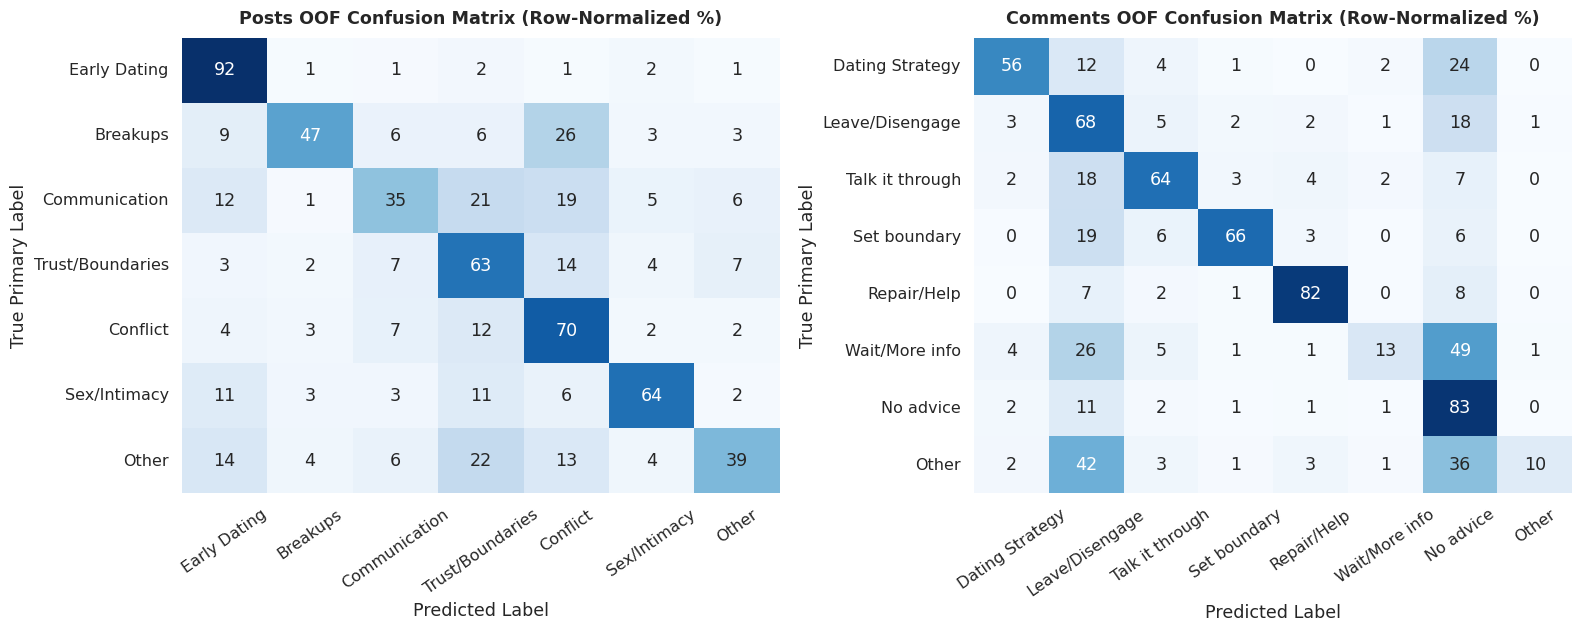

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)

# Define the 7-class post labels used in v2
POST_LABELS_7CLASS = [
    "Early Dating",
    "Breakups",
    "Communication",
    "Trust/Boundaries",
    "Conflict",
    "Sex/Intimacy",
    "Other"
]

# ==============================================================================
# 1. ROW-NORMALIZED OUT-OF-FOLD CONFUSION MATRICES (SUP V2)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Map post labels to merged classes
y_true_posts_merged = posts_eval_df["true_primary"].apply(
    lambda x: "Trust/Boundaries" if str(x) in {"Trust", "Boundaries"} else str(x)
).values

configs = [
    (
        axes[0],
        y_true_posts_merged,
        post_v2_artifacts["oof_pred"],
        POST_LABELS_7CLASS,
        "Posts OOF Confusion Matrix (Row-Normalized %)",
    ),
    (
        axes[1],
        comments_eval_df["true_primary"].values,
        comment_v2_artifacts["oof_pred"],
        CANONICAL_COMMENT_LABELS,
        "Comments OOF Confusion Matrix (Row-Normalized %)",
    ),
]

for ax, y_true, y_pred, labels, title in configs:
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_pct = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0) * 100

    sns.heatmap(
        cm_pct,
        annot=True,
        fmt=".0f",
        cmap="Blues",
        cbar=False,
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
        vmin=0,
        vmax=85,
    )
    ax.set_title(title, fontweight="bold", pad=10)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Primary Label")
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


# ==============================================================================
# 2. EMPIRICAL P(COMMENT ADVICE | POST PROBLEM) HEATMAP
# ==============================================================================
if (
    "posts_unann_df" in globals()
    and "comments_unann_df" in globals()
    and "id" in posts_unann_df.columns
    and "parentPostId" in comments_unann_df.columns
):
    merged = comments_unann_df.merge(
        posts_unann_df[["id", "pred_label", "pred_confidence"]],
        left_on="parentPostId",
        right_on="id",
        suffixes=("_comment", "_post"),
    )
    # Filter to reasonably confident predictions (>= 0.30) for cleaner signal
    confident_pairs = merged[
        (merged["pred_confidence_post"] >= 0.30)
        & (merged["pred_confidence_comment"] >= 0.30)
    ]

    ct = (
        pd.crosstab(
            confident_pairs["pred_label_post"],
            confident_pairs["pred_label_comment"],
            normalize="index",
        )
        .reindex(index=POST_LABELS_7CLASS, columns=CANONICAL_COMMENT_LABELS)
        .fillna(0.0)
        * 100
    )

    plt.figure(figsize=(11, 6.5))
    sns.heatmap(
        ct,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        cbar_kws={"label": "Row Share (%)"},
    )
    plt.title(
        f"Empirical P(Comment Advice | Post Problem) — Confident Pairs (N={len(confident_pairs):,})",
        fontweight="bold",
        pad=12,
    )
    plt.xlabel("Predicted Comment Advice Action")
    plt.ylabel("Predicted Post Problem Category")
    plt.xticks(rotation=30, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

### Synthetic Post & Expected Advice Simulation


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize

generated_posts_df = pd.DataFrame([
   {
        "post_id": 1,
        "title": "First date went surprisingly well, should I text tonight or wait until tomorrow?",
        "bodyText": "We stayed at the wine bar for three hours and he walked me to my car, so I do not want to seem overeager.",
    },
    {
        "post_id": 2,
        "title": "We have been dating for a month and still haven't had the exclusivity talk.",
        "bodyText": "We see each other twice a week and act like a couple, yet neither of us has brought up deleting dating apps.",
    },
    {
        "post_id": 3,
        "title": "Is it normal to feel anxious right after a really good early date?",
        "bodyText": "Everything went smoothly tonight, but now my brain is overthinking every detail and waiting for a catch.",
    },
    {
        "post_id": 4,
        "title": "How do you pack up the last box of your ex's things without breaking down?",
        "bodyText": "We broke up a month ago and their hoodie and books are still sitting in my closet.",
    },
    {
        "post_id": 5,
        "title": "My ex wants to meet for coffee to 'stay on good terms' after a messy breakup.",
        "bodyText": "We hurt each other a lot in the final weeks, and I worry meeting up will just reopen old wounds.",
    },
    {
        "post_id": 6,
        "title": "Feeling guilty that I feel relieved after ending a two-year relationship.",
        "bodyText": "Nothing terrible happened, we just grew apart, yet I feel lighter than I have in months.",
    },
    {
        "post_id": 7,
        "title": "He takes everything I say as criticism when I try to bring up small issues.",
        "bodyText": "Even when I use 'I feel' statements, he gets defensive and turns it into how he is always the bad guy.",
    },
    {
        "post_id": 8,
        "title": "Long-distance relationship: how do we stay connected when time zones clash?",
        "bodyText": "Between work and sleep schedules, we only get a narrow window to talk and feel like we are drifting.",
    },
    {
        "post_id": 9,
        "title": "My partner says 'I'm fine' when something is clearly wrong.",
        "bodyText": "I can tell they are upset by their tone and posture, but pushing for details makes them pull away further.",
    },
    {
        "post_id": 10,
        "title": "My partner hides their screen whenever I walk into the room.",
        "bodyText": "We have been together for two years and never used to act secretive around each other's phones.",
    },
    {
        "post_id": 11,
        "title": "Caught my partner in a small lie about money and now I question bigger things.",
        "bodyText": "It was not a huge amount, but lying about it casually made me wonder what else gets brushed under the rug.",
    },
    {
        "post_id": 12,
        "title": "My partner stays close friends with an ex they used to have feelings for.",
        "bodyText": "They hang out one-on-one occasionally, and while I try not to be controlling, it makes me uneasy.",
    },
    {
        "post_id": 13,
        "title": "My partner expects me to drop plans whenever they have a stressful day.",
        "bodyText": "I want to support them, but canceling on friends or workouts every week is burning me out.",
    },
    {
        "post_id": 14,
        "title": "How do I tell my partner I don't want to share our passwords right now?",
        "bodyText": "We are moving toward a serious stage and they asked for my accounts, which feels too fast for me.",
    },
    {
        "post_id": 15,
        "title": "My partner borrows my car and returns it on empty with trash inside.",
        "bodyText": "I have asked nicely several times to refuel and clean up, and I am tired of nagging.",
    },
    {
        "post_id": 16,
        "title": "We keep score during fights instead of actually solving the problem.",
        "bodyText": "Whenever one person brings up an issue, the other immediately lists past mistakes to even the score.",
    },
    {
        "post_id": 17,
        "title": "Holiday travel plans are causing huge tension between us.",
        "bodyText": "We both want to visit family in different cities and neither of us wants to compromise this year.",
    },
    {
        "post_id": 18,
        "title": "Our sex life has become strictly scheduled and feels like a chore.",
        "bodyText": "We made a plan to stay consistent, which helped frequency, but spontaneity and desire feel missing.",
    },
    {
        "post_id": 19,
        "title": "What is one piece of relationship advice you used to believe that turned out wrong?",
        "bodyText": "Curious how people's perspectives have shifted with experience over the years.",
    },
])

# Ensure text cleaning function is available
if "deduplicate_df" not in globals():
    def deduplicate_df(df: pd.DataFrame, is_post: bool = True, drop_empty: bool = True) -> pd.DataFrame:
        out = df.copy()
        if is_post:
            title = out.get("title", pd.Series("", index=out.index)).fillna("").astype(str).str.strip()
            body = out.get("bodyText", pd.Series("", index=out.index)).fillna("").astype(str).str.strip()
            combined = (title + " — " + body).str.strip(" —")
        else:
            combined = out.get("bodyText", pd.Series("", index=out.index)).fillna("").astype(str)
        out["_clean_text"] = combined.str.replace(r"\s+", " ", regex=True).str.strip()
        if drop_empty:
            out = out[out["_clean_text"] != ""].copy()
        return out.reset_index(drop=True)

scored_posts_df = deduplicate_df(generated_posts_df, is_post=True, drop_empty=True)

# Map correct active models and variables from earlier execution steps
active_st_model = st_model
active_post_clf = post_models["Sup: MiniLM + LogisticRegression"]
active_bge_model = bge_model
active_comment_artifacts = comment_v2_artifacts

# Prepare pipeline lookup cache for the synthetic texts if not already cached
for text in scored_posts_df["_clean_text"]:
    if text not in active_post_clf.named_steps["emb"].lookup:
        # Encode single text and cache it
        encoded_vec = active_st_model.encode([text], show_progress_bar=False, normalize_embeddings=True)[0]
        active_post_clf.named_steps["emb"].lookup[text] = encoded_vec

# --- 1. Pass raw clean text list to Post Winner Model (MiniLM Pipeline) ---
post_probs = active_post_clf.predict_proba(scored_posts_df["_clean_text"].tolist())
post_best_idx = np.argmax(post_probs, axis=1)
scored_posts_df["most_likely_post_label"] = active_post_clf.classes_[post_best_idx]
scored_posts_df["post_confidence"] = np.round(post_probs[np.arange(len(scored_posts_df)), post_best_idx], 4)

# --- 2. Prepare Inputs for Comment Winner Model (BGE + Cues + TF-IDF) ---
# 2a. Embed
X_gen_bge = active_bge_model.encode(
    scored_posts_df["_clean_text"].tolist(),
    batch_size=64,
    show_progress_bar=False,
    normalize_embeddings=True,
)

# 2b. Aux Cues block
meta_feats_gen = extract_comment_meta_features(scored_posts_df)
aux_scaled_gen = active_comment_artifacts["scaler"].transform(meta_feats_gen)
aux_norm_gen = normalize(aux_scaled_gen, norm="l2")

# 2c. TF-IDF block
X_tfidf_gen = active_comment_artifacts["tfidf"].transform(scored_posts_df["_clean_text"]).toarray()

# 2d. Hybrid Fusion
X_gen_fused = np.hstack([
    normalize(X_gen_bge, norm="l2"),
    active_comment_artifacts["aux_weight"] * aux_norm_gen,
    active_comment_artifacts["tfidf_weight"] * X_tfidf_gen,
])

advice_probs = active_comment_artifacts["clf"].predict_proba(X_gen_fused)
advice_classes = np.array(active_comment_artifacts["clf"].classes_)

# Case-insensitive mask to exclude "no advice"
allowed_mask = np.array([str(c).strip().lower() != "no advice" for c in advice_classes])
filtered_classes = advice_classes[allowed_mask]
filtered_probs = advice_probs[:, allowed_mask]

# Re-normalize probabilities across allowed actionable classes
filtered_probs_norm = filtered_probs / np.clip(filtered_probs.sum(axis=1, keepdims=True), 1e-12, None)

advice_best_idx = np.argmax(filtered_probs_norm, axis=1)
scored_posts_df["most_likely_advice"] = filtered_classes[advice_best_idx]
scored_posts_df["advice_confidence"] = np.round(
    filtered_probs_norm[np.arange(len(scored_posts_df)), advice_best_idx], 4
)

for i, row in scored_posts_df.iterrows():
    print(
        f"{i + 1:2d}. [Post: {row['most_likely_post_label']} ({row['post_confidence']:.4f}) | "
        f"Advice: {row['most_likely_advice']} ({row['advice_confidence']:.4f})] {row['title']}"
    )

 1. [Post: Early Dating (0.8251) | Advice: Dating Strategy (0.7470)] First date went surprisingly well, should I text tonight or wait until tomorrow?
 2. [Post: Early Dating (0.7948) | Advice: Talk it through (0.4044)] We have been dating for a month and still haven't had the exclusivity talk.
 3. [Post: Early Dating (0.7042) | Advice: Dating Strategy (0.8859)] Is it normal to feel anxious right after a really good early date?
 4. [Post: Breakups (0.6985) | Advice: Leave/Disengage (0.4642)] How do you pack up the last box of your ex's things without breaking down?
 5. [Post: Early Dating (0.8205) | Advice: Leave/Disengage (0.7191)] My ex wants to meet for coffee to 'stay on good terms' after a messy breakup.
 6. [Post: Breakups (0.6651) | Advice: Leave/Disengage (0.8110)] Feeling guilty that I feel relieved after ending a two-year relationship.
 7. [Post: Communication (0.6658) | Advice: Leave/Disengage (0.8471)] He takes everything I say as criticism when I try to bring up small issue

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import normalize


# ==============================================================================
# 1. ALIGN ANNOTATED POSTS WITH THEIR ANNOTATED COMMENTS
# ==============================================================================
posts_lookup = posts_eval_df[["id", "_clean_text", "title", "true_primary"]].copy()
posts_lookup["id"] = posts_lookup["id"].astype(str).str.strip()

comm_annotated = comments_eval_df.copy()
comm_annotated["parentPostId"] = comm_annotated["parentPostId"].astype(str).str.strip()

# Keep only comments whose parent post is in `posts_eval_df`
paired_df = comm_annotated.merge(
    posts_lookup,
    left_on="parentPostId",
    right_on="id",
    suffixes=("_comment", "_post"),
    how="inner",
)

print(
    f"Matched {len(paired_df)} annotated comments across "
    f"{paired_df['parentPostId'].nunique()} unique annotated posts."
)


# ==============================================================================
# 2. GROUPED 80/20 SPLIT BY POST ID (ZERO LEAKAGE BETWEEN TRAIN & TEST POSTS)
# ==============================================================================
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(
    gss.split(paired_df, paired_df["true_primary_comment"], groups=paired_df["parentPostId"])
)

train_comm_df = paired_df.iloc[train_idx].reset_index(drop=True)
test_comm_df = paired_df.iloc[test_idx].reset_index(drop=True)

# Unique held-out test posts (input X will be ONLY the post's `_clean_text`)
test_posts_df = (
    test_comm_df[["parentPostId", "_clean_text_post", "title", "true_primary_post"]]
    .drop_duplicates(subset=["parentPostId"])
    .rename(columns={"_clean_text_post": "_clean_text"})
    .reset_index(drop=True)
)

print(f"Train split: {len(train_comm_df)} comments ({train_comm_df['parentPostId'].nunique()} posts)")
print(f"Test split : {len(test_comm_df)} comments ({len(test_posts_df)} held-out posts)")


# ==============================================================================
# 3. TRAIN COMMENT CLASSIFIER STRICTLY ON TRAINING COMMENTS
# ==============================================================================
train_comm_df["_clean_text"] = train_comm_df["_clean_text_comment"]
train_texts = train_comm_df["_model_text"].tolist()
X_emb_tr = bge_model.encode(
    train_texts, batch_size=64, show_progress_bar=False, normalize_embeddings=True
)
aux_raw_tr = extract_comment_meta_features(train_comm_df)
train_texts = train_comm_df["_model_text"].tolist()
X_emb_tr = bge_model.encode(
    train_texts, batch_size=64, show_progress_bar=False, normalize_embeddings=True
)
aux_raw_tr = extract_comment_meta_features(train_comm_df)

# Build fused features using your existing helper (dummy 1-row eval, discarded)
X_tr_base, _, fold_tfidf, fold_scaler = build_fused_features(
    train_texts=train_texts,
    eval_texts=train_texts[:1],
    emb_tr=X_emb_tr,
    emb_ev=X_emb_tr[:1],
    aux_raw_tr=aux_raw_tr,
    aux_raw_ev=aux_raw_tr[:1],
    aux_weight=0.35,
    tfidf_weight=0.50,
)

# Secondary-label augmentation strictly on training comments
y_tr_list = train_comm_df["true_primary_comment"].tolist()
base_w = [1.0] * len(train_comm_df)
X_tr_rows = [X_tr_base]

if "true_secondary_comment" in train_comm_df.columns:
    aug_rows = []
    for i, r in train_comm_df.iterrows():
        sec_lbl = r["true_secondary_comment"]
        prim_lbl = r["true_primary_comment"]
        if pd.notna(sec_lbl) and sec_lbl != prim_lbl:
            aug_rows.append(X_tr_base[i])
            y_tr_list.append(sec_lbl)
            base_w.append(0.45)
    if aug_rows:
        X_tr_rows.append(np.vstack(aug_rows))

X_tr = np.vstack(X_tr_rows)
sample_w = compute_smoothed_sample_weights(y_tr_list, base_w, weight_power=0.40)

fold_comment_clf = LogisticRegression(C=1.5, max_iter=1500, random_state=42)
fold_comment_clf.fit(X_tr, y_tr_list, sample_weight=sample_w)


# ==============================================================================
# 4. PREDICT ADVICE ON HELD-OUT TEST POSTS (USING POST TEXT ONLY)
# ==============================================================================
X_test_post_emb = bge_model.encode(
    test_posts_df["_clean_text"].tolist(),
    batch_size=64,
    show_progress_bar=False,
    normalize_embeddings=True,
)
meta_feats_te = extract_comment_meta_features(test_posts_df)
aux_norm_te = normalize(fold_scaler.transform(meta_feats_te), norm="l2")
X_tfidf_te = fold_tfidf.transform(test_posts_df["_clean_text"]).toarray()

X_te_fused = np.hstack([
    normalize(X_test_post_emb, norm="l2"),
    0.35 * aux_norm_te,
    0.50 * X_tfidf_te,
])

raw_probs = fold_comment_clf.predict_proba(X_te_fused)
classes = np.array(fold_comment_clf.classes_)

# Exclude "No advice" and renormalize across actionable classes (same as your script)
allowed_mask = np.array([str(c).strip().lower() != "no advice" for c in classes])
action_classes = classes[allowed_mask]
action_probs = raw_probs[:, allowed_mask]
action_probs_norm = action_probs / np.clip(action_probs.sum(axis=1, keepdims=True), 1e-12, None)

top1_idx = np.argmax(action_probs_norm, axis=1)
top2_idx = np.argsort(action_probs_norm, axis=1)[:, -2:]

test_posts_df["pred_advice_top1"] = action_classes[top1_idx]
test_posts_df["pred_advice_conf"] = np.round(
    action_probs_norm[np.arange(len(test_posts_df)), top1_idx], 4
)
test_posts_df["pred_advice_top2"] = [
    set(action_classes[row_idx]) for row_idx in top2_idx
]


# ==============================================================================
# 5. EVALUATE AGAINST GROUND-TRUTH ANNOTATED COMMENTS ON HELD-OUT POSTS
# ==============================================================================
# Build ground-truth actionable advice sets per held-out post
valid_test_comms = test_comm_df[
    test_comm_df["true_primary_comment"].str.lower() != "no advice"
].copy()

gt_advice_by_post = {}
for pid, grp in valid_test_comms.groupby("parentPostId"):
    labels = set(grp["true_primary_comment"].dropna())
    if "true_secondary_comment" in grp.columns:
        sec_labels = set(grp["true_secondary_comment"].dropna()) - {"No advice"}
        labels |= sec_labels
    gt_advice_by_post[pid] = labels

eval_posts = test_posts_df[test_posts_df["parentPostId"].isin(gt_advice_by_post)].copy().reset_index(drop=True)
eval_posts["true_advice_set"] = eval_posts["parentPostId"].map(gt_advice_by_post)

top1_hits = [
    row["pred_advice_top1"] in row["true_advice_set"]
    for _, row in eval_posts.iterrows()
]
top2_hits = [
    len(row["pred_advice_top2"] & row["true_advice_set"]) > 0
    for _, row in eval_posts.iterrows()
]

print(f"\n================ ZERO-SHOT POST -> ADVICE EVALUATION (N={len(eval_posts)} Held-Out Posts) ================")
print(f"Top-1 Advice Hit Rate (predicted advice matches >=1 gold comment): {np.mean(top1_hits):.3f}")
print(f"Top-2 Advice Hit Rate (top-2 predictions match >=1 gold comment)  : {np.mean(top2_hits):.3f}")

print("\n--- Predicted Advice Distribution vs. Ground-Truth Comment Shares on Test Posts (%) ---")
dist_comp = pd.DataFrame({
    "True_Comment_Share_%": valid_test_comms["true_primary_comment"].value_counts(normalize=True) * 100,
    "Post_Model_Pred_Share_%": eval_posts["pred_advice_top1"].value_counts(normalize=True) * 100,
}).fillna(0.0).round(1)
print(dist_comp.to_string())

print("\n--- Sample Held-Out Test Posts: Predicted Advice vs. Actual Annotated Advice ---")
for i, row in eval_posts.head(15).iterrows():
    hit_mark = "✓" if row["pred_advice_top1"] in row["true_advice_set"] else "✗"
    print(
        f"{i + 1:2d}. [{hit_mark}] Post Problem: {row['true_primary_post']:<16} | "
        f"Pred Advice: {row['pred_advice_top1']:<16} ({row['pred_advice_conf']:.2f}) | "
        f"Gold Advice: {sorted(row['true_advice_set'])}"
    )

Matched 13927 annotated comments across 1300 unique annotated posts.
Train split: 11227 comments (1040 posts)
Test split : 2700 comments (260 held-out posts)
